<a href="https://colab.research.google.com/github/yuniecorn-dev/esaa_assignment2/blob/main/ESAA_1102_assignment16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5장 합성곱신경망
## 5.2 합성곱 신경망 맛보기
###fashion_mnist 데이터셋
- 데이터: 운동화, 셔츠, 샌들 같은 작은 이미지의 모음
- 0~9까지 정수값 -> 이미지의 클래스를 나타냄

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
train_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            train=False, transform=transforms.Compose([transforms.ToTensor()]))

파라미터

- 첫 번째 파라미터: 내려받을 위치 지정
- download: True일 때 첫 번째 파라미터 위치에 해당 데이터셋이 있는지 확인 후 내려받음
- transform: 이미지를 텐서(0~1)로 변경

In [ ]:
train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=100) # (1)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size=100)

- 데이터 로더
  - `torch.utils.data.DataLoader()`: 원하는 크기의 배치 단위로 데이터 불러오거나 순서 무작위로 섞이도록 함
  - 파라미터
    - 첫번째 : 데이터 불러올 데이터셋 지정
    - batch_size: 데이터를 배치로 묶음

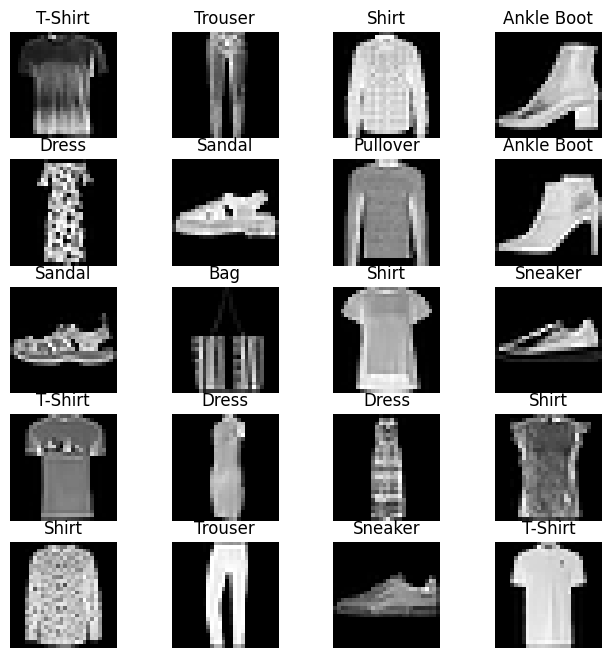

In [ ]:
labels_map = {0: 'T-Shirt', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4:'Coat',
              5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}

fig = plt.figure(figsize=(8,8));
columns = 4;
rows = 5;
for i in range(1, columns*rows +1):
    img_xy = np.random.randint(len(train_dataset));
    img = train_dataset[img_xy][0][0,:,:]
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis('off')
    plt.imshow(img, cmap='gray')
plt.show()

`np.random` : 무작위로 데이터를 생성할 때 사용.

`np.random.randint()` : 이산 형 분포를 갖는 데이터에서 무작위 표본을 추출할 때 시용

`random.randint(len(train_dataset))`의 의미: 0~(train_dataset의 길이) 값을 갖는 분포에서 랜덤한 숫자 한 개를 생성하라는 의미
`train_dataset[imag_xy][0][0,:,:]의 의미: train_dataset에서 [img_xy][0][0,:,:]에 해당하는 요소 갓ㅂ을 가져오겠다는 의미

In [ ]:
class FashionDNN(nn.Module):
    def __init__(self):  # (1)
        super(FashionDNN, self).__init__()
        self.fc1 = nn.Linear(in_features=784, out_features=256)  # (2)
        self.drop = nn.Dropout(0.25) # (3)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, input_data):     # (4)
        out = input_data.view(-1, 784) # (5)
        out = F.relu(self.fc1(out))    # (6)
        out = self.drop(out)
        out = F.relu(self.fc2(out))
        out = self.fc3(out)
        return out

1. class 형태의 모델은 항상 torch.nn.Module 상속받음
  - init(): 객체가 갖는 속성 값을 초기화, 객체 생성될 때 자동으로 호출됨
  - super(FasionDNN, self).init(): nn.Module클래스 상속받는다는 의미


2. nn: 딥러닝 모델 구성에 필요한 모듈이 모여있는 패키지
  - in_features
  - out_features

3. torch.nn.Dropout(p)
p만큼의 비율로 텐서 값 0 되며 0이 되지 않는 값들은 기존 값에 (1/(1-p))만큼 곱해짐
4. forward() : 모데링 학습 데이터를 입력받아서 순전파 학습을 진행시킴. 객체를 데이터와 함께 호출하면 자동으로 실행됨. 순전파 연산이란 H(x) 식에 입력 x로부터 예측된 y를 얻는것

5. view: 텐서 크기 변경

6. 활성화 함수 지정

- F.relu(): forward() 함수에서 정의
- nn.ReLU(): init() 함수에서 정의


In [ ]:
learning_rate = 0.001;
model = FashionDNN();
model.to(device)

criterion = nn.CrossEntropyLoss (); # 분류 문제에서 사용하는 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


- 옵티마이저를 위한 경사하강법은 Adam 사용함.
- 학습률 lr: 0.001을 사용한다는 의미

In [ ]:
num_epochs = 5
count = 0

loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train) # 학습 데이터를 모델에 적용
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50): # count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss. data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                                                             accuracy))

Iteration: 500, Loss: 0.5767973065376282, Accuracy: 82.56999969482422%
Iteration: 1000, Loss: 0.40831267833709717, Accuracy: 84.31999969482422%
Iteration: 1500, Loss: 0.34617000818252563, Accuracy: 84.68000030517578%
Iteration: 2000, Loss: 0.3576290011405945, Accuracy: 85.68000030517578%
Iteration: 2500, Loss: 0.2707376182079315, Accuracy: 85.75%
Iteration: 3000, Loss: 0.33446547389030457, Accuracy: 86.72000122070312%


(1), (1)' 일반적으로 배열이나 행렬과 같은 리스트 Ii 를 사용하는 방법은 다음과 같습니다.

- (1)과 같이 비어 있는 배열이나 행렬을 만듭니다.
- (1)'처럼 append 메서드를 이용하여 데이터를 하나씩 추가합니다.

(2) for 구문을 사용하여 레코드(행 가로줄)를 하나씩 가져옵니다. 이때 for x, y in train: 과 같이 in 앞에 변수를두개 지정해주면 레코드에서 요소 두 개를 꺼내 오겠다는 의미입니다.

(3) 모댈이 데이터를 처리하기 위해서는 모댈과 데이터가 동일한 장치 (CPU 또는 GPU) 에 있어야 합니다.

(4) Autograd는 자동 미분을 수행하는 파이토치의 핵심 패키지로， 자동 미분에 대한 값을 저장하기 위해 테이프(tape) 를 사용합니다.

(5) 분류 문제에 대한 정확도는 전체 에측에 대한 정확한 예측의 비율로 표현할 수 있다.

In [ ]:
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

1. nn.Sequential
- `__init__()`에서 사용할 네트워크 모델들을 정의해 줌.
- 순전파의 여러 개의 계층을 하나의 컨테이너에 구현 -> 가독성 올라감.
2. 합성곱층: 이미지의 특징 추출
- 커널이라는 nxm의 행렬이 높이x너비 크기의 이미지를 처음부터 끝까지 훑으면서 각 원소끼리 곱한 후 모두 더한 값을 출력
3. BatchNorm2d
- 학습 과정에서 각 배치 단위별로 데이터가 다양한 분포를 가지더라도 평균
과 분산을 이용하여 정규화하는 것을 의미

4. MaxPool2d : 이미지 크기 축소시킴

5. 줄어든 출력크기는 최종적으로 분류를 담당하는 완전연결층으로 전달됨
6. 합성곱층에서 완전연결층으로 변경되기 때문에 데이터의 형태를 차원으로 바꾸어 줌.
- out.size(0) =100
- out.view(out.size(0), -1)

In [ ]:
learning_rate = 0.001;
model = FashionCNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [ ]:
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train)
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50):
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss.data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                accuracy))

Iteration: 500, Loss: 0.429565966129303, Accuracy: 88.05000305175781%
Iteration: 1000, Loss: 0.283208429813385, Accuracy: 87.20999908447266%
Iteration: 1500, Loss: 0.27600210905075073, Accuracy: 88.06999969482422%
Iteration: 2000, Loss: 0.2510767877101898, Accuracy: 89.58999633789062%
Iteration: 2500, Loss: 0.14706186950206757, Accuracy: 89.62000274658203%
Iteration: 3000, Loss: 0.15160953998565674, Accuracy: 90.05999755859375%
